# Task 1 - Concepts, Splits and Leakage

## Step 1 - Dataset Inspection

### Objectives
1. Load the LendingClub dataset.
2. Understand the dataset dimensions.
3. Inspect column names and data types.
4. Identify missing values.
5. Identify duplicate records.
6. Examine the target variable distribution.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
file_path = Path("../data/raw/lending_club_loans.csv")

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Dataset Shape:", df.shape) #(rows,columns)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (396030, 27)
Number of Rows: 396030
Number of Columns: 27


In [4]:
df.head()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


In [5]:
df.tail()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
396025,10000.0,60 months,10.99,217.38,B,B4,licensed bankere,2 years,RENT,40000.0,...,6.0,0.0,1990.0,34.3,23.0,w,INDIVIDUAL,0.0,0.0,"12951 Williams Crossing\r\nJohnnyville, DC 30723"
396026,21000.0,36 months,12.29,700.42,C,C1,Agent,5 years,MORTGAGE,110000.0,...,6.0,0.0,43263.0,95.7,8.0,f,INDIVIDUAL,1.0,0.0,"0114 Fowler Field Suite 028\r\nRachelborough, ..."
396027,5000.0,36 months,9.99,161.32,B,B1,City Carrier,10+ years,RENT,56500.0,...,15.0,0.0,32704.0,66.9,23.0,f,INDIVIDUAL,0.0,0.0,"953 Matthew Points Suite 414\r\nReedfort, NY 7..."
396028,21000.0,60 months,15.31,503.02,C,C2,"Gracon Services, Inc",10+ years,MORTGAGE,64000.0,...,9.0,0.0,15704.0,53.8,20.0,f,INDIVIDUAL,5.0,0.0,"7843 Blake Freeway Apt. 229\r\nNew Michael, FL..."
396029,2000.0,36 months,13.61,67.98,C,C2,Internal Revenue Service,10+ years,RENT,42996.0,...,3.0,0.0,4292.0,91.3,19.0,f,INDIVIDUAL,NaN,0.0,"787 Michelle Causeway\r\nBriannaton, AR 48052"


In [6]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Column Names:
['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'title', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'address']

Data Types:
loan_amnt               float64
term                        str
int_rate                float64
installment             float64
grade                       str
sub_grade                   str
emp_title                   str
emp_length                  str
home_ownership              str
annual_inc              float64
verification_status         str
issue_d                     str
loan_status                 str
purpose                     str
title                       str
dti                     float64
earliest_cr_line            str
open_acc                float64
pub_rec           

In [7]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

emp_title               22927
emp_length              18301
title                    1756
revol_util                276
mort_acc                37795
pub_rec_bankruptcies      535
dtype: int64


In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
mort_acc,37795,9.543469
emp_title,22927,5.789208
emp_length,18301,4.621115
title,1756,0.443401
pub_rec_bankruptcies,535,0.135091
revol_util,276,0.069692


In [9]:
print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [10]:
if "loan_status" in df.columns:
    print(df["loan_status"].value_counts(dropna=False))
else:
    print("loan_status column not found!")

loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64


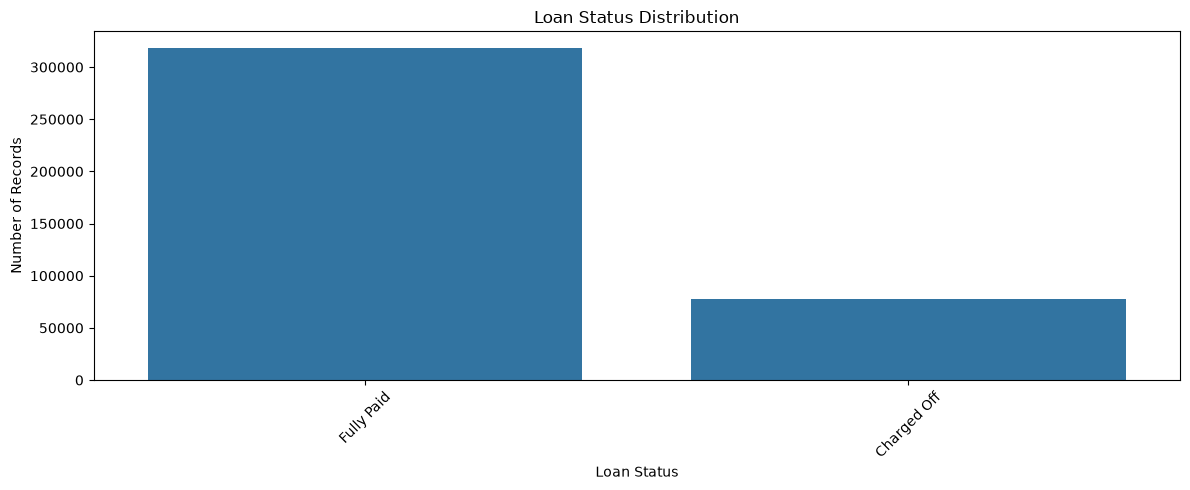

In [11]:
if "loan_status" in df.columns:
    plt.figure(figsize=(12, 5))

    sns.countplot(
        data=df,
        x="loan_status",
        order=df["loan_status"].value_counts().index
    )

    plt.title("Loan Status Distribution")
    plt.xlabel("Loan Status")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [12]:
y = df["loan_status"]


## Step 2 - Feature and Target Identification

Identify the classification target, inspect loan status
categories, and distinguish numerical, categorical,
and post-loan information.

In [13]:
# Display all available columns

print("Available Columns:")
for column in df.columns:
    print(column)

Available Columns:
loan_amnt
term
int_rate
installment
grade
sub_grade
emp_title
emp_length
home_ownership
annual_inc
verification_status
issue_d
loan_status
purpose
title
dti
earliest_cr_line
open_acc
pub_rec
revol_bal
revol_util
total_acc
initial_list_status
application_type
mort_acc
pub_rec_bankruptcies
address


In [14]:
# Examine loan status categories

print("Loan Status Distribution:")
print(df["loan_status"].value_counts(dropna=False))

Loan Status Distribution:
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64


In [15]:
# Identify numerical columns

numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']

Categorical Columns:
['term', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'title', 'earliest_cr_line', 'initial_list_status', 'application_type', 'address']


C:\Users\Admin\AppData\Local\Temp\ipykernel_19224\3381189132.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [16]:
expected_columns = [
    "loan_amnt",
    "annual_inc",
    "dti",
    "int_rate",
    "installment",
    "loan_status",
    "term",
    "grade",
    "home_ownership",
    "purpose",
    "emp_length"
]

for column in expected_columns:
    print(
        column,
        ":", 
        "Available" if column in df.columns else "Not Available"
    )

loan_amnt : Available
annual_inc : Available
dti : Available
int_rate : Available
installment : Available
loan_status : Available
term : Available
grade : Available
home_ownership : Available
purpose : Available
emp_length : Available


In [17]:
random_state=42

In [18]:
stratify=y

## Step 3 - Train, Validation and Test Split

Split the dataset into:
- 60% Training
- 20% Validation
- 20% Testing

Use random_state=42 and stratified sampling
to maintain the class distribution.

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
# Keep only completed loan outcomes

model_df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

# Encode the binary target

model_df["default"] = (
    model_df["loan_status"] == "Charged Off"
).astype(int)

# Separate features and target

X = model_df.drop(
    columns=["loan_status", "default"]
)

y = model_df["default"]

In [21]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

In [22]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [23]:
print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nTarget Shapes:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

Training Shape: (237618, 26)
Validation Shape: (79206, 26)
Testing Shape: (79206, 26)

Target Shapes:
Training: (237618,)
Validation: (79206,)
Testing: (79206,)


In [24]:
print("Original Distribution:")
print(y.value_counts(normalize=True))

print("\nTraining Distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation Distribution:")
print(y_val.value_counts(normalize=True))

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True))

Original Distribution:
default
0    0.803871
1    0.196129
Name: proportion, dtype: float64

Training Distribution:
default
0    0.80387
1    0.19613
Name: proportion, dtype: float64

Validation Distribution:
default
0    0.803866
1    0.196134
Name: proportion, dtype: float64

Testing Distribution:
default
0    0.803878
1    0.196122
Name: proportion, dtype: float64


In [25]:
total_records = len(model_df)

print(
    "Training Percentage:",
    round(len(X_train) / total_records * 100, 2)
)

print(
    "Validation Percentage:",
    round(len(X_val) / total_records * 100, 2)
)

print(
    "Testing Percentage:",
    round(len(X_test) / total_records * 100, 2)
)

Training Percentage: 60.0
Validation Percentage: 20.0
Testing Percentage: 20.0


In [26]:
print("Dataset columns:")
for column in df.columns:
    print(column)

print("\nLoan status distribution:")
print(df["loan_status"].value_counts(dropna=False))

Dataset columns:
loan_amnt
term
int_rate
installment
grade
sub_grade
emp_title
emp_length
home_ownership
annual_inc
verification_status
issue_d
loan_status
purpose
title
dti
earliest_cr_line
open_acc
pub_rec
revol_bal
revol_util
total_acc
initial_list_status
application_type
mort_acc
pub_rec_bankruptcies
address

Loan status distribution:
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64


In [27]:
print(df.columns.tolist())

print(df["loan_status"].value_counts(dropna=False))

['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'title', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'address']
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64


In [28]:
from sklearn.model_selection import train_test_split

# Create a copy
model_df = df.copy()

# Create binary target
model_df["default"] = (
    model_df["loan_status"] == "Charged Off"
).astype(int)

# Select safe features
feature_cols = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "initial_list_status",
    "application_type",
    "mort_acc",
    "pub_rec_bankruptcies"
]

X = model_df[feature_cols]
y = model_df["default"]

# First split: 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: 20% validation, 20% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nClass distribution:")
print("Training:\n", y_train.value_counts(normalize=True))
print("Validation:\n", y_val.value_counts(normalize=True))
print("Testing:\n", y_test.value_counts(normalize=True))

Training: (237618, 21)
Validation: (79206, 21)
Testing: (79206, 21)

Class distribution:
Training:
 default
0    0.80387
1    0.19613
Name: proportion, dtype: float64
Validation:
 default
0    0.803866
1    0.196134
Name: proportion, dtype: float64
Testing:
 default
0    0.803878
1    0.196122
Name: proportion, dtype: float64


In [29]:
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTotal records:", len(X_train) + len(X_val) + len(X_test))

print("\nSplit percentages:")
print("Training:", round(len(X_train) / len(X) * 100, 2), "%")
print("Validation:", round(len(X_val) / len(X) * 100, 2), "%")
print("Testing:", round(len(X_test) / len(X) * 100, 2), "%")

Training records: 237618
Validation records: 79206
Testing records: 79206

Total records: 396030

Split percentages:
Training: 60.0 %
Validation: 20.0 %
Testing: 20.0 %


In [7]:
print("df exists:", "df" in globals())
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())

df exists: False
X_train exists: False
y_train exists: False


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/lending_club_loans.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (396030, 27)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


In [9]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nLoan status distribution:")
print(df["loan_status"].value_counts(dropna=False))

Rows and columns: (396030, 27)

Column names:
['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'title', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'address']

Loan status distribution:
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/lending_club_loans.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (396030, 27)


In [16]:
from sklearn.model_selection import train_test_split

# Create a copy of the dataset
model_df = df.copy()

# Create binary target
model_df["default"] = (
    model_df["loan_status"] == "Charged Off"
).astype(int)

# Select features
feature_cols = [
    "loan_amnt", "term", "int_rate", "installment",
    "grade", "sub_grade", "emp_length", "home_ownership",
    "annual_inc", "verification_status", "purpose", "dti",
    "open_acc", "pub_rec", "revol_bal", "revol_util",
    "total_acc", "initial_list_status", "application_type",
    "mort_acc", "pub_rec_bankruptcies"
]

X = model_df[feature_cols]
y = model_df["default"]

# Split into training and temporary datasets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Split temporary dataset into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (237618, 21)
Validation: (79206, 21)
Testing: (79206, 21)


In [14]:
print("df exists:", "df" in globals())
print(df.head())


df exists: True
   loan_amnt        term  int_rate  installment grade sub_grade  \
0    10000.0   36 months     11.44       329.48     B        B4   
1     8000.0   36 months     11.99       265.68     B        B5   
2    15600.0   36 months     10.49       506.97     B        B3   
3     7200.0   36 months      6.49       220.65     A        A2   
4    24375.0   60 months     17.27       609.33     C        C5   

                 emp_title emp_length home_ownership  annual_inc  ...  \
0                Marketing  10+ years           RENT    117000.0  ...   
1          Credit analyst     4 years       MORTGAGE     65000.0  ...   
2             Statistician   < 1 year           RENT     43057.0  ...   
3          Client Advocate    6 years           RENT     54000.0  ...   
4  Destiny Management Inc.    9 years       MORTGAGE     55000.0  ...   

  open_acc pub_rec revol_bal revol_util total_acc  initial_list_status  \
0     16.0     0.0   36369.0       41.8      25.0                   

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Handle missing numerical values
numeric_transformer = SimpleImputer(strategy="median")

# Handle missing categorical values and encode them
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

In [1]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
print("X_train:", "X_train" in globals())
print("y_train:", "y_train" in globals())
print("preprocessor:", "preprocessor" in globals())
print("Pipeline:", "Pipeline" in globals())

X_train: False
y_train: False
preprocessor: False
Pipeline: True


In [4]:
import sys
print(sys.executable)

c:\Users\Admin\Desktop\python_new\github\week-2-weekly-assessment\.venv\Scripts\python.exe


In [3]:
import sklearn
print(sklearn.__version__)

1.9.1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/lending_club_loans.csv")

print("Dataset:", df.shape)

Dataset: (396030, 27)


In [2]:
from sklearn.model_selection import train_test_split

model_df = df.copy()

model_df["default"] = (
    model_df["loan_status"] == "Charged Off"
).astype(int)

feature_cols = [
    "loan_amnt", "term", "int_rate", "installment",
    "grade", "sub_grade", "emp_length", "home_ownership",
    "annual_inc", "verification_status", "purpose", "dti",
    "open_acc", "pub_rec", "revol_bal", "revol_util",
    "total_acc", "initial_list_status", "application_type",
    "mort_acc", "pub_rec_bankruptcies"
]

X = model_df[feature_cols]
y = model_df["default"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (237618, 21)
Validation: (79206, 21)
Testing: (79206, 21)


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

depths = [1, 3, 5, 10, None]

results = []

for depth in depths:

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)

    train_accuracy = accuracy_score(
        y_train, train_predictions
    )

    val_accuracy = accuracy_score(
        y_val, val_predictions
    )

    results.append({
        "max_depth": str(depth),
        "training_accuracy": train_accuracy,
        "validation_accuracy": val_accuracy
    })

results_df = pd.DataFrame(results)

print(results_df)

  max_depth  training_accuracy  validation_accuracy
0         1           0.803870             0.803866
1         3           0.803870             0.803866
2         5           0.805263             0.804661
3        10           0.812430             0.801088
4      None           1.000000             0.708557


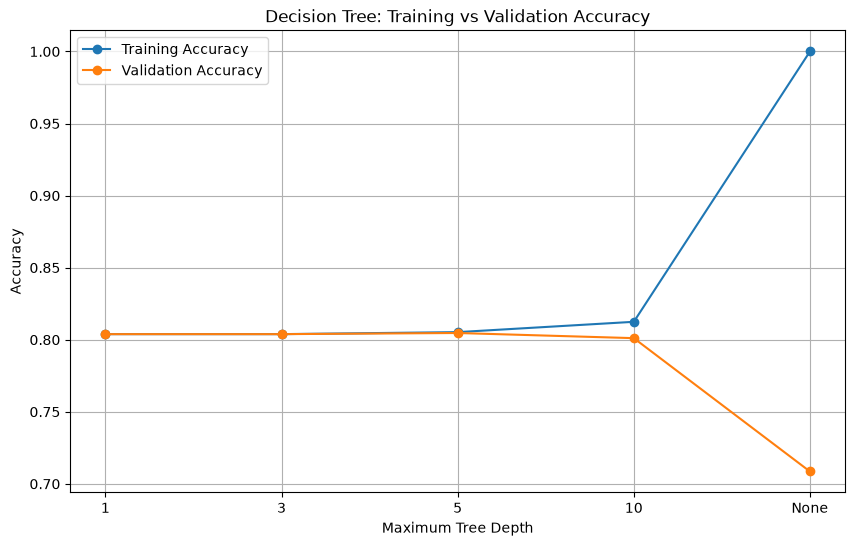

In [5]:
plt.figure(figsize=(10, 6))

plt.plot(
    results_df["max_depth"],
    results_df["training_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    results_df["max_depth"],
    results_df["validation_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
logistic_preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Complete Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", logistic_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [7]:
cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)

print("Individual fold scores:", cv_scores)

print("Mean accuracy:", cv_scores.mean())

print("Standard deviation:", cv_scores.std())

Individual fold scores: [0.80597172 0.8049617  0.80658194 0.80516802 0.80603076]
Mean accuracy: 0.8057428297230367
Standard deviation: 0.0005966503973762927


In [8]:
cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)

print("Individual fold scores:", cv_scores)

print("Mean accuracy:", cv_scores.mean())

print("Standard deviation:", cv_scores.std())

Individual fold scores: [0.80597172 0.8049617  0.80658194 0.80516802 0.80603076]
Mean accuracy: 0.8057428297230367
Standard deviation: 0.0005966503973762927


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Select numerical features
X_numeric = X.select_dtypes(include=["number"])

# Create a separate demonstration split
X_demo_train, X_demo_test = train_test_split(
    X_numeric,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# INCORRECT: Fit scaler using the entire dataset
wrong_scaler = StandardScaler()
wrong_scaler.fit(X_numeric)

# CORRECT: Fit scaler using training data only
correct_scaler = StandardScaler()
correct_scaler.fit(X_demo_train)

print("Incorrect scaler mean:")
print(wrong_scaler.mean_)

print("\nCorrect scaler mean:")
print(correct_scaler.mean_)

print("\nAre the scaler means identical?")
print(np.allclose(
    wrong_scaler.mean_,
    correct_scaler.mean_
))

Incorrect scaler mean:
[1.41138881e+04 1.36394000e+01 4.31849698e+02 7.42031758e+04
 1.73795136e+01 1.13111532e+01 1.78191046e-01 1.58445399e+04
 5.37917486e+01 2.54147438e+01 1.81399082e+00 1.21647556e-01]

Correct scaler mean:
[1.41205905e+04 1.36411748e+01 4.32056342e+02 7.42271283e+04
 1.73793899e+01 1.13132212e+01 1.78584956e-01 1.58679150e+04
 5.38217178e+01 2.54232034e+01 1.81646190e+00 1.21637168e-01]

Are the scaler means identical?
False


In [10]:
cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

### Data Leakage Demonstration

Data leakage occurs when information from outside the training dataset
influences the model training process.

For example, fitting a StandardScaler on the entire dataset allows
validation and test data to influence the calculated mean and standard deviation.

This can produce misleading evaluation results because the model's
preprocessing has already used information from unseen data.

To prevent data leakage, we should split the dataset first and fit
preprocessing transformations only on the training data.

Using Pipeline and ColumnTransformer ensures that preprocessing is
fitted correctly within each cross-validation fold.